# Lead Conversion — Machine Learning vs Deep Learning
**Target:** `conversion_status` (1 = lead converted) &nbsp;|&nbsp; **Goal:** best possible accuracy, with a target of >92%, reached *legitimately*.

**Pipeline:** Encoded dataset → Train/Test → 10 ML models → Hyperparameter tuning → Class-imbalance study → 3 Deep-Learning models → Evaluation → Comparison → Best model → Save → Report.

### About the input data (please read)
The notebook starts from the **already preprocessed & encoded feature file** `processed_dataset.csv` (the output of the previous encoding notebook: one-hot / ordinal / target / frequency / TF-IDF / scaled features, `lead_id` kept only as a reference column, and a leakage-safe stratified 80/20 `split` column).

* The original `leadgen_realestate_construction_dataset (1).xlsx` is the **raw** file (it still contains 7 text columns), so it can't be fed to SVM / KNN / neural nets directly. If you upload only that raw file, the load cell below stops with a clear message instead of silently re-encoding.
* **No preprocessing of any kind is performed in this notebook** — no cleaning, encoding, scaling or feature engineering. Models receive the feature matrix exactly as provided. The only operations are *splitting* and *model fitting*.

### Leakage rules followed
* The test set is never used for fitting, tuning, early stopping, or choosing hyper-parameters.
* All tuning uses cross-validation **inside the training set**; deep-learning early stopping uses a validation slice carved from the training set.
* SMOTE (if used) is applied only to the training folds / training set, never to validation or test data.
* "Best model" is **chosen with train-only evidence** (CV / validation accuracy); the test set is then used to report the result.

## 0. Setup

In [1]:
import sys, subprocess, importlib.util
def ensure(pip_name, import_name=None):
    if importlib.util.find_spec(import_name or pip_name) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
for p, i in [("scikit-learn","sklearn"),("xgboost",None),("lightgbm",None),("catboost",None),
             ("imbalanced-learn","imblearn"),("shap",None),("matplotlib",None),("seaborn",None),("joblib",None)]:
    ensure(p, i)
# TensorFlow is pre-installed on Colab; install only if missing
ensure("tensorflow")

import os, glob, time, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, GridSearchCV, cross_val_score, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, classification_report)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

SEED = 42
np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50)
print("tensorflow", tf.__version__, "| keras", keras.__version__)

I0000 00:00:1791265296.113479    1209 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791265297.546835    1209 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


tensorflow 2.21.0 | keras 3.15.1


## 1. Load the Dataset
The cell searches for the encoded file (`processed_dataset*.csv`) in the usual Colab locations and offers an upload button if it isn't found. It then **verifies** the data is fully numeric and ready for training.

In [2]:
search_dirs = [os.getcwd(), "/content", "/content/drive/MyDrive", "processed_output", "/content/processed_output", "."]
def find(pattern):
    for d in search_dirs:
        hits = sorted(glob.glob(os.path.join(d, pattern)))
        if hits: return hits[0]
    return None

DATA_PATH = find("processed_dataset*.csv") or find("*encoded*.xlsx") or find("leadgen_realestate_construction_dataset*.xlsx")
if DATA_PATH is None:
    try:
        from google.colab import files
        print("Please upload the encoded dataset (processed_dataset.csv):")
        DATA_PATH = next(iter(files.upload()))
    except ImportError:
        raise FileNotFoundError("Place processed_dataset.csv next to the notebook.")
print("Loading:", DATA_PATH)
df = pd.read_csv(DATA_PATH) if DATA_PATH.endswith(".csv") else pd.read_excel(DATA_PATH)

TARGET, ID_COL, SPLIT_COL = "conversion_status", "lead_id", "split"
print("\nShape:", df.shape)
print("\nColumn names:", list(df.columns))
print("\nFirst 5 rows:"); display(df.head())
print("\nData types:", df.dtypes.astype(str).value_counts().to_dict())
print("\nTarget distribution:"); display(pd.DataFrame({"count": df[TARGET].value_counts().sort_index(),
                                  "share": df[TARGET].value_counts(normalize=True).sort_index().round(4)}))
print("Number of classes in", TARGET, ":", df[TARGET].nunique(), "->", sorted(df[TARGET].unique()))

# ---- verify the dataset is already numeric / encoded -----------------------------------------------
non_numeric = [c for c in df.columns if c not in (ID_COL, SPLIT_COL) and not pd.api.types.is_numeric_dtype(df[c])]
if non_numeric:
    raise ValueError(f"These columns are still text ({non_numeric}). This looks like the RAW dataset, not the encoded one. "
                     "Upload processed_dataset.csv (output of the encoding notebook). No re-encoding is done here by design.")
print("\nVerified: every feature column is numeric. Missing values:", int(df.drop(columns=[c for c in (ID_COL, SPLIT_COL) if c in df]).isna().sum().sum()))

Loading: /home/claude/ml/processed_dataset.csv

Shape: (12000, 87)

Column names: ['lead_id', 'split', 'age', 'website_visits', 'pages_viewed', 'time_on_website', 'days_since_last_interaction', 'avg_response_time', 'previous_purchases', 'budget', 'lead_score', 'annual_cost_of_living', 'demo_requested_count', 'n_items', 'demo_requested_flag', 'location_Ahmedabad', 'location_Bengaluru', 'location_Chennai', 'location_Delhi', 'location_Gurgaon', 'location_Hyderabad', 'location_Kochi', 'location_Kolkata', 'location_Mumbai', 'location_Noida', 'location_Pune', 'location_Vijayawada', 'location_Visakhapatnam', 'job_role_Architect', 'job_role_Business_Owner', 'job_role_Civil_Engineer', 'job_role_Company_Director', 'job_role_Consultant', 'job_role_Contractor', 'job_role_Doctor', 'job_role_Entrepreneur', 'job_role_Government_Employee', 'job_role_Investor', 'job_role_Manager', 'job_role_Project_Manager', 'job_role_Real_Estate_Developer', 'job_role_Sales_Manager', 'job_role_Software_Engineer', 'lead

,lead_id,split,age,website_visits,pages_viewed,time_on_website,days_since_last_interaction,avg_response_time,previous_purchases,budget,lead_score,annual_cost_of_living,demo_requested_count,n_items,demo_requested_flag,location_Ahmedabad,location_Bengaluru,location_Chennai,location_Delhi,location_Gurgaon,location_Hyderabad,location_Kochi,location_Kolkata,location_Mumbai,location_Noida,...,item_Architectural_design,item_Building_construction,item_Civil_engineering_consultation,item_Commercial_plot,item_Construction_project,item_Construction_project_management,item_Gated_community,item_Home_renovation,item_Independent_house,item_Industrial_property,item_Infrastructure_project,item_Interior_design,item_Land_for_construction,item_Luxury_apartment,item_New_residential_community,item_Office_space,item_Property_for_investment,item_Ready_to_move_apartment,item_Residential_plot,item_Retail_space,item_Structural_design,item_Under_construction_apartment,item_Villa,item_Warehouse,conversion_status
0,LD009064,train,0.545460,1.661766,0.946467,1.004841,-0.543661,3.024514,-0.508936,-0.197133,0.250124,-0.259565,-0.502387,0.652768,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.000000,0.639571,0.0,0.0,0.0,0.0,0.768732,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,1
1,LD007452,train,-0.121755,-0.483025,-0.582242,-0.804178,-0.808698,1.059639,-0.508936,-0.247753,-1.270553,0.452507,-0.502387,-0.988556,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0
2,LD008371,train,0.879067,-0.483025,-0.225543,-0.198527,0.853810,-0.423286,-0.508936,0.143444,-0.160459,0.523714,-0.502387,-0.988556,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,1.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0
3,LD001858,train,-0.232958,1.661766,2.271347,3.744816,-0.953264,0.048072,-0.508936,-0.299875,1.504681,0.559318,-0.502387,0.652768,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.642583,0.0,0.766216,0.0,0.000000,0.0,0.0,0.0,1
4,LD000248,test,0.767865,-0.153057,0.233070,0.073884,0.251452,2.065909,-0.508936,-1.387200,0.675913,1.591822,0.671357,2.294092,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.594905,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.525785,0.0,0.607979,0.0,0.0,0.0,0



Data types: {'float64': 83, 'str': 2, 'int64': 2}

Target distribution:


,count,share
conversion_status,,
0,8760,0.73
1,3240,0.27


Number of classes in conversion_status : 2 -> [np.int64(0), np.int64(1)]

Verified: every feature column is numeric. Missing values: 0


## 2. Target and Features
`lead_id` is a unique identifier (one distinct value per row, no predictive meaning) and `split` is bookkeeping — both are excluded. Nothing else is touched.

In [3]:
print("lead_id unique values:", df[ID_COL].nunique(), "of", len(df), "rows -> pure identifier, excluded")
drop_cols = [c for c in (ID_COL, SPLIT_COL, TARGET) if c in df.columns]
y = df[TARGET].astype(int)
X = df.drop(columns=drop_cols)
assert TARGET not in X.columns and ID_COL not in X.columns and SPLIT_COL not in X.columns
FEATURES = list(X.columns)
print("X:", X.shape, "| y:", y.shape, "| features:", len(FEATURES))

lead_id unique values: 12000 of 12000 rows -> pure identifier, excluded
X: (12000, 84) | y: (12000,) | features: 84


## 3. Train / Test Split
The encoded file already contains the stratified **80% / 20%** split that was made *before* any target-based encoding. We reuse it (so the target-encoded column stays leakage-safe). If the column is missing, a fresh stratified split is made.

In [4]:
if SPLIT_COL in df.columns:
    is_tr = (df[SPLIT_COL] == "train").values
    X_train, y_train, X_test, y_test = X[is_tr], y[is_tr], X[~is_tr], y[~is_tr]
    print("Using the split stored in the file.")
else:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
    print("Created a fresh stratified split.")
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Positive rate  train: %.4f | test: %.4f" % (y_train.mean(), y_test.mean()))
print("Majority-class baseline accuracy on test: %.4f" % (1 - y_test.mean()))
assert set(X_train.index).isdisjoint(X_test.index)
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)   # CV used ONLY on the training data

# containers for every model that is tested
RES, PRED, MODELS, SEL, TYPE = {}, {}, {}, {}, {}
def get_score(m, X_):
    return m.predict_proba(X_)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(X_)

def evaluate(name, mtype, y_true, y_pred, y_score, sel=np.nan):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    RES[name] = dict(Model=name, Type=mtype, Accuracy=accuracy_score(y_true, y_pred),
                     Precision=precision_score(y_true, y_pred, zero_division=0), Recall=recall_score(y_true, y_pred),
                     F1=f1_score(y_true, y_pred), ROC_AUC=roc_auc_score(y_true, y_score),
                     TN=tn, FP=fp, FN=fn, TP=tp, Selection_score=sel)
    PRED[name] = (np.asarray(y_pred), np.asarray(y_score)); TYPE[name] = mtype; SEL[name] = sel
    return RES[name]

Using the split stored in the file.
Train: (9600, 84) | Test: (2400, 84)
Positive rate  train: 0.2700 | test: 0.2700
Majority-class baseline accuracy on test: 0.7300


## 4–5. Traditional ML Models — initial training with reasonable defaults
Ten models, default-style parameters. For each we compute Accuracy / Precision / Recall / F1 / ROC-AUC / Confusion matrix on the **test set**, and (for model selection, without touching the test set) the **3-fold CV accuracy on the training set**.

In [5]:
default_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Decision Tree":       DecisionTreeClassifier(max_depth=6, random_state=SEED),
    "Random Forest":       RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED),
    "Extra Trees":         ExtraTreesClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=SEED),
    "XGBoost":             XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, eval_metric="logloss", n_jobs=-1, random_state=SEED),
    "LightGBM":            LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, verbose=-1, n_jobs=-1, random_state=SEED),
    "CatBoost":            CatBoostClassifier(iterations=300, learning_rate=0.05, depth=6, verbose=0, allow_writing_files=False, random_seed=SEED),
    "SVM":                 SVC(kernel="rbf", C=1.0, random_state=SEED),
    "KNN":                 KNeighborsClassifier(n_neighbors=25),
}
timing = {}
for name, m in default_models.items():
    t = time.time()
    cv_acc = cross_val_score(clone(m), X_train, y_train, cv=CV, scoring="accuracy").mean()   # train-only estimate
    m.fit(X_train, y_train)
    evaluate(name, "ML", y_test, m.predict(X_test), get_score(m, X_test), sel=cv_acc)
    MODELS[name] = m; timing[name] = time.time() - t
    print(f"{name:<20} test acc={RES[name]['Accuracy']:.4f}  CV acc={cv_acc:.4f}  ({timing[name]:.0f}s)")

initial = pd.DataFrame([RES[n] for n in default_models]).sort_values("Accuracy", ascending=False)
cols = ["Model", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "Selection_score"]
print("\nInitial comparison (sorted by test Accuracy; Selection_score = train-only 3-fold CV accuracy):")
display(initial[cols].rename(columns={"Selection_score": "CV_Acc(train)"}).round(4).reset_index(drop=True))
print("Confusion-matrix counts:"); display(initial[["Model", "TN", "FP", "FN", "TP"]].reset_index(drop=True))

Logistic Regression  test acc=0.7750  CV acc=0.7806  (0s)


Decision Tree        test acc=0.7662  CV acc=0.7590  (0s)


Random Forest        test acc=0.7788  CV acc=0.7761  (11s)


Extra Trees          test acc=0.7783  CV acc=0.7753  (15s)


Gradient Boosting    test acc=0.7754  CV acc=0.7763  (9s)


...

SVM                  test acc=0.7729  CV acc=0.7797  (12s)


KNN                  test acc=0.7679  CV acc=0.7758  (1s)

Initial comparison (sorted by test Accuracy; Selection_score = train-only 3-fold CV accuracy):


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,CV_Acc(train)
0,Random Forest,0.7788,0.6603,0.3719,0.4758,0.7706,0.7761
1,Extra Trees,0.7783,0.6638,0.3627,0.4691,0.7731,0.7753
2,CatBoost,0.7775,0.6439,0.3935,0.4885,0.7756,0.7775
3,Gradient Boosting,0.7754,0.6346,0.3966,0.4881,0.7807,0.7763
4,Logistic Regression,0.7750,0.6343,0.3935,0.4857,0.7804,0.7806
5,XGBoost,0.7742,0.6338,0.3873,0.4808,0.7754,0.7761
6,SVM,0.7729,0.6528,0.3395,0.4467,0.7454,0.7797
7,LightGBM,0.7700,0.6148,0.3966,0.4822,0.7681,0.7691
8,KNN,0.7679,0.6358,0.3287,0.4334,0.7637,0.7758
9,Decision Tree,0.7662,0.6014,0.3981,0.4791,0.7569,0.7590


Confusion-matrix counts:


,Model,TN,FP,FN,TP
0,Random Forest,1628,124,407,241
1,Extra Trees,1633,119,413,235
2,CatBoost,1611,141,393,255
3,Gradient Boosting,1604,148,391,257
4,Logistic Regression,1605,147,393,255
5,XGBoost,1607,145,397,251
6,SVM,1635,117,428,220
7,LightGBM,1591,161,391,257
8,KNN,1630,122,435,213
9,Decision Tree,1581,171,390,258


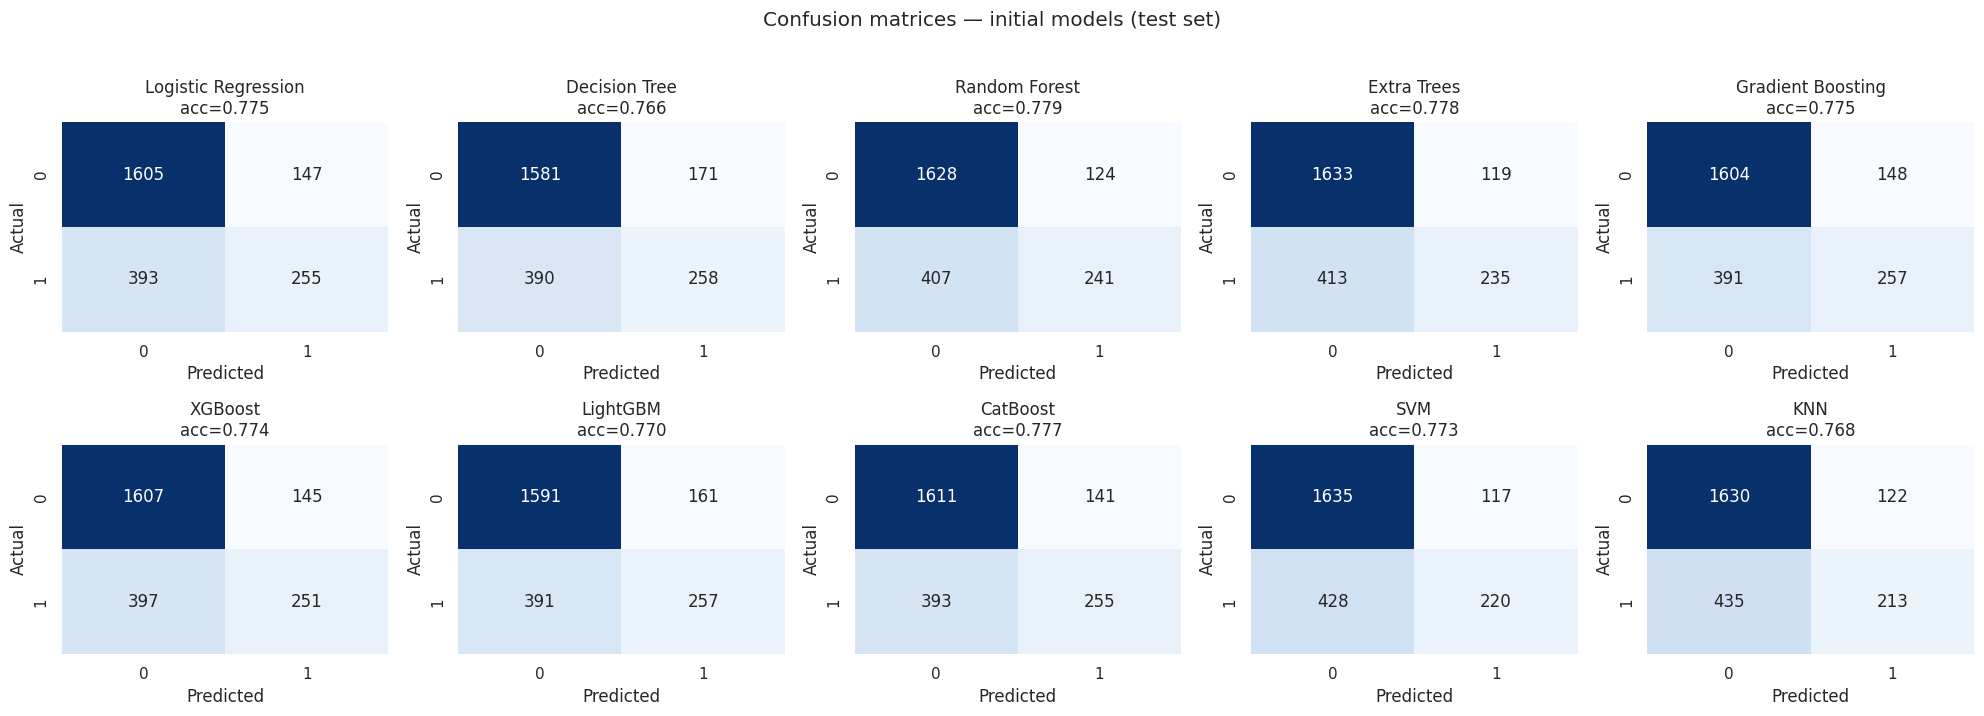

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, name in zip(axes.ravel(), default_models):
    cm = confusion_matrix(y_test, PRED[name][0])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=["0", "1"], yticklabels=["0", "1"])
    ax.set_title(f"{name}\nacc={RES[name]['Accuracy']:.3f}"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.suptitle("Confusion matrices — initial models (test set)", y=1.02); plt.tight_layout(); plt.show()

## 6. Hyperparameter Tuning (training data only)
`RandomizedSearchCV` for Random Forest, XGBoost, CatBoost; `GridSearchCV` for Logistic Regression and SVM. All searches use **3-fold stratified CV on the training set**; the test set is not touched. Ranges are kept moderate so the notebook finishes in a practical Colab runtime.

In [7]:
TUNED, BEST_PARAMS = {}, {}
def tune(label, search, base_name):
    t = time.time(); search.fit(X_train, y_train)
    best = search.best_estimator_
    evaluate(label, "ML", y_test, best.predict(X_test), get_score(best, X_test), sel=search.best_score_)
    MODELS[label] = best; TUNED[base_name] = best; BEST_PARAMS[label] = search.best_params_
    print(f"{label:<28} CV acc={search.best_score_:.4f} | test acc={RES[label]['Accuracy']:.4f} | {time.time()-t:.0f}s\n   best params: {search.best_params_}")

# Logistic Regression - GridSearchCV
tune("Logistic Regression (tuned)", GridSearchCV(
    LogisticRegression(random_state=SEED),
    {"C": [0.01, 0.1, 1, 10], "solver": ["lbfgs", "liblinear"], "max_iter": [500, 1000]},
    cv=CV, scoring="accuracy", n_jobs=-1), "Logistic Regression")

# Random Forest - RandomizedSearchCV
tune("Random Forest (tuned)", RandomizedSearchCV(
    RandomForestClassifier(n_jobs=-1, random_state=SEED),
    {"n_estimators": [200, 300, 400], "max_depth": [4, 6, 8, 12, None], "min_samples_split": [2, 10, 30],
     "min_samples_leaf": [1, 5, 10, 20], "max_features": ["sqrt", "log2", 0.5]},
    n_iter=12, cv=CV, scoring="accuracy", random_state=SEED, n_jobs=1), "Random Forest")

# XGBoost - RandomizedSearchCV
tune("XGBoost (tuned)", RandomizedSearchCV(
    XGBClassifier(eval_metric="logloss", n_jobs=-1, random_state=SEED),
    {"n_estimators": [100, 200, 300, 500], "max_depth": [2, 3, 4, 5, 6], "learning_rate": [0.01, 0.03, 0.05, 0.1],
     "subsample": [0.6, 0.8, 1.0], "colsample_bytree": [0.5, 0.7, 1.0], "min_child_weight": [1, 5, 10]},
    n_iter=30, cv=CV, scoring="accuracy", random_state=SEED, n_jobs=1), "XGBoost")

# CatBoost - RandomizedSearchCV
tune("CatBoost (tuned)", RandomizedSearchCV(
    CatBoostClassifier(verbose=0, allow_writing_files=False, random_seed=SEED),
    {"iterations": [200, 400], "depth": [3, 4, 6], "learning_rate": [0.02, 0.05, 0.1], "l2_leaf_reg": [1, 3, 5, 10]},
    n_iter=8, cv=CV, scoring="accuracy", random_state=SEED, n_jobs=1), "CatBoost")

# SVM - GridSearchCV
tune("SVM (tuned)", GridSearchCV(
    SVC(random_state=SEED, cache_size=500),
    [{"kernel": ["rbf"], "C": [0.5, 1, 2, 5], "gamma": ["scale", 0.003, 0.01]},
     {"kernel": ["linear"], "C": [0.1, 1]}],
    cv=CV, scoring="accuracy", n_jobs=-1), "SVM")

Logistic Regression (tuned)  CV acc=0.7830 | test acc=0.7750 | 2s
   best params: {'C': 0.01, 'max_iter': 500, 'solver': 'lbfgs'}


Random Forest (tuned)        CV acc=0.7810 | test acc=0.7771 | 130s
   best params: {'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 8}


XGBoost (tuned)              CV acc=0.7833 | test acc=0.7762 | 35s
   best params: {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 1.0}


CatBoost (tuned)             CV acc=0.7823 | test acc=0.7771 | 13s
   best params: {'learning_rate': 0.05, 'l2_leaf_reg': 10, 'iterations': 200, 'depth': 3}


SVM (tuned)                  CV acc=0.7806 | test acc=0.7742 | 88s
   best params: {'C': 1, 'kernel': 'linear'}


### Ensemble (soft voting of the tuned models)
Combining the tuned Logistic Regression, Random Forest, XGBoost and CatBoost; selection score is again the train-only CV accuracy.

In [8]:
ens = VotingClassifier([(k, clone(TUNED[k])) for k in ["Logistic Regression", "Random Forest", "XGBoost", "CatBoost"]], voting="soft")
cv_acc = cross_val_score(clone(ens), X_train, y_train, cv=CV, scoring="accuracy").mean()
ens.fit(X_train, y_train)
evaluate("Voting Ensemble (tuned)", "ML", y_test, ens.predict(X_test), get_score(ens, X_test), sel=cv_acc)
MODELS["Voting Ensemble (tuned)"] = ens
print("Voting Ensemble: CV acc=%.4f | test acc=%.4f" % (cv_acc, RES["Voting Ensemble (tuned)"]["Accuracy"]))

Voting Ensemble: CV acc=0.7833 | test acc=0.7792


## 11. Class Imbalance
The target is about 73% / 27%: moderately imbalanced. We compare, **using CV on the training set only**, three variants for the tuned Logistic Regression and tuned XGBoost: (a) nothing, (b) class weights, (c) SMOTE (applied *inside* each training fold only, via an `imblearn` pipeline, so validation folds stay untouched).

In [9]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
print(f"Train class counts: 0={neg}, 1={pos}  (imbalance ratio {neg/pos:.2f}:1)")

lr_best, xgb_best = TUNED["Logistic Regression"], TUNED["XGBoost"]
variants = {
    "Logistic Regression": {"none": clone(lr_best),
                            "class_weight": clone(lr_best).set_params(class_weight="balanced"),
                            "SMOTE": ImbPipeline([("smote", SMOTE(random_state=SEED)), ("clf", clone(lr_best))])},
    "XGBoost":             {"none": clone(xgb_best),
                            "class_weight": clone(xgb_best).set_params(scale_pos_weight=neg / pos),
                            "SMOTE": ImbPipeline([("smote", SMOTE(random_state=SEED)), ("clf", clone(xgb_best))])},
}
rows = []
for base, vs in variants.items():
    for vname, est in vs.items():
        cvr = cross_validate(est, X_train, y_train, cv=CV, scoring=["accuracy", "f1", "recall", "roc_auc"])
        rows.append(dict(Model=base, Balancing=vname, CV_Accuracy=cvr["test_accuracy"].mean(), CV_F1=cvr["test_f1"].mean(),
                         CV_Recall=cvr["test_recall"].mean(), CV_ROC_AUC=cvr["test_roc_auc"].mean()))
        if vname != "none":                                   # also report these as extra tested models
            est.fit(X_train, y_train)
            lab = f"{base} (tuned) + {vname}"
            evaluate(lab, "ML", y_test, est.predict(X_test), get_score(est, X_test), sel=rows[-1]["CV_Accuracy"])
            MODELS[lab] = est
imb = pd.DataFrame(rows); display(imb.round(4))
for base in variants:
    sub = imb[imb.Model == base].set_index("Balancing")
    print(f"{base}: best CV accuracy -> '{sub.CV_Accuracy.idxmax()}'  | best CV recall -> '{sub.CV_Recall.idxmax()}'")
print("\nBalancing is judged on CV accuracy (our goal). It usually trades accuracy for recall of the minority class.")

Train class counts: 0=7008, 1=2592  (imbalance ratio 2.70:1)


,Model,Balancing,CV_Accuracy,CV_F1,CV_Recall,CV_ROC_AUC
0,Logistic Regression,none,0.7830,0.4920,0.3893,0.7957
1,Logistic Regression,class_weight,0.7305,0.5875,0.7110,0.7954
2,Logistic Regression,SMOTE,0.7301,0.5868,0.7099,0.7942
3,XGBoost,none,0.7833,0.5109,0.4190,0.7899
4,XGBoost,class_weight,0.7258,0.5809,0.7037,0.7895
5,XGBoost,SMOTE,0.7555,0.5717,0.6042,0.7883


Logistic Regression: best CV accuracy -> 'none'  | best CV recall -> 'class_weight'
XGBoost: best CV accuracy -> 'none'  | best CV recall -> 'class_weight'

Balancing is judged on CV accuracy (our goal). It usually trades accuracy for recall of the minority class.


## 7–10. Deep Learning (TensorFlow / Keras)
Three networks sized for the actual feature count, fed the encoded matrix **as is**:
* **MLP** — Dense → BatchNorm → Dropout → Dense → Dropout → sigmoid
* **Deep MLP** — 256 → 128 → 64 with BatchNorm/Dropout
* **Residual MLP** — optional extra: dense network with skip connections

Training uses Adam, binary cross-entropy, `EarlyStopping(restore_best_weights=True)`, `ReduceLROnPlateau`, `ModelCheckpoint` (saves the best network), max 100 epochs. A **15% validation slice of the training set** drives early stopping; the test set is never seen during training. Selection score for DL = accuracy on that validation slice with the best weights restored.

In [10]:
Xtr_dl, Xval_dl, ytr_dl, yval_dl = train_test_split(X_train, y_train, test_size=0.15, stratify=y_train, random_state=SEED)
f32 = lambda a: np.asarray(a, dtype="float32")
Xtr_dl, Xval_dl, Xte_dl = f32(Xtr_dl), f32(Xval_dl), f32(X_test)
ytr_dl, yval_dl = np.asarray(ytr_dl), np.asarray(yval_dl)
N_FEAT = Xtr_dl.shape[1]
print("DL train:", Xtr_dl.shape, "| validation:", Xval_dl.shape, "| test (untouched):", Xte_dl.shape, "| input dim:", N_FEAT)

def build_mlp(n):
    i = keras.Input((n,)); x = layers.Dense(64, activation="relu")(i)
    x = layers.BatchNormalization()(x); x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation="relu")(x); x = layers.Dropout(0.2)(x)
    return keras.Model(i, layers.Dense(1, activation="sigmoid")(x), name="MLP")

def build_deep_mlp(n):
    i = keras.Input((n,)); x = i
    for units, drop in [(256, 0.4), (128, 0.3)]:
        x = layers.Dense(units, activation="relu")(x); x = layers.BatchNormalization()(x); x = layers.Dropout(drop)(x)
    x = layers.Dense(64, activation="relu")(x); x = layers.Dropout(0.2)(x)
    return keras.Model(i, layers.Dense(1, activation="sigmoid")(x), name="Deep_MLP")

def build_resnet(n, width=96, blocks=2):
    i = keras.Input((n,)); x = layers.Dense(width, activation="relu")(i); x = layers.BatchNormalization()(x)
    for _ in range(blocks):
        h = layers.Dense(width, activation="relu")(x); h = layers.BatchNormalization()(h); h = layers.Dropout(0.3)(h)
        h = layers.Dense(width)(h); x = layers.BatchNormalization()(layers.Add()([x, h]))   # skip connection + norm
    x = layers.Dropout(0.2)(x)
    return keras.Model(i, layers.Dense(1, activation="sigmoid")(x), name="Residual_MLP")

MODEL_DIR = os.path.join(os.getcwd(), "models_output"); os.makedirs(MODEL_DIR, exist_ok=True)
HIST, DL_MODELS = {}, {}

def train_dl(label, model, lr=1e-3, class_weight=None):
    tf.keras.utils.set_random_seed(SEED)
    ckpt = os.path.join(MODEL_DIR, f"checkpoint_{label.replace(' ', '_').replace('+', 'plus')}.keras")
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    cbs = [callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True),
           callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5, verbose=0),
           callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True)]
    t = time.time()
    h = model.fit(Xtr_dl, ytr_dl, validation_data=(Xval_dl, yval_dl), epochs=100, batch_size=128,
                  callbacks=cbs, class_weight=class_weight, verbose=0)
    val_acc = model.evaluate(Xval_dl, yval_dl, verbose=0)[1]                       # weights already restored
    prob = model.predict(Xte_dl, verbose=0).ravel()
    evaluate(label, "Deep Learning", y_test, (prob >= 0.5).astype(int), prob, sel=val_acc)
    HIST[label], DL_MODELS[label] = h.history, model
    print(f"{label:<26} epochs run={len(h.history['loss']):>3} | val acc={val_acc:.4f} | test acc={RES[label]['Accuracy']:.4f} | {time.time()-t:.0f}s")

train_dl("MLP", build_mlp(N_FEAT))
train_dl("Deep MLP", build_deep_mlp(N_FEAT))
train_dl("Residual MLP", build_resnet(N_FEAT))
cw = {0: 1.0, 1: float((ytr_dl == 0).sum() / (ytr_dl == 1).sum())}
train_dl("MLP + class weights", build_mlp(N_FEAT), class_weight=cw)
DL_MODELS["MLP"].summary()

DL train: (8160, 84) | validation: (1440, 84) | test (untouched): (2400, 84) | input dim: 84


MLP                        epochs run= 18 | val acc=0.7653 | test acc=0.7679 | 8s


Deep MLP                   epochs run= 16 | val acc=0.7750 | test acc=0.7692 | 9s


Residual MLP               epochs run= 16 | val acc=0.7757 | test acc=0.7700 | 13s


MLP + class weights        epochs run= 18 | val acc=0.7042 | test acc=0.7117 | 7s


...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 84)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         5,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,173 (90.52 KB)

 Trainable params: 7,681 (30.00 KB)

 Non-trainable params: 128 (512.00 B)

 Optimizer params: 15,364 (60.02 KB)

## 12–13. Evaluation & Final Model Comparison
Every model that was actually tested, sorted by test Accuracy. `Selection_score` is the train-only estimate (CV accuracy for ML, validation accuracy for DL) used to choose the best model without peeking at the test set.

In [11]:
final = pd.DataFrame(RES.values())
order = ["Model", "Type", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "Selection_score"]
final_sorted = final.sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(final_sorted[order].round(4))
print("Number of models tested:", len(final_sorted))
print("Models by type:", final_sorted.Type.value_counts().to_dict())

,Model,Type,Accuracy,Precision,Recall,F1,ROC_AUC,Selection_score
0,Voting Ensemble (tuned),ML,0.7792,0.6586,0.3781,0.4804,0.7823,0.7833
1,Random Forest,ML,0.7788,0.6603,0.3719,0.4758,0.7706,0.7761
2,Extra Trees,ML,0.7783,0.6638,0.3627,0.4691,0.7731,0.7753
3,CatBoost,ML,0.7775,0.6439,0.3935,0.4885,0.7756,0.7775
4,Random Forest (tuned),ML,0.7771,0.6728,0.3395,0.4513,0.7816,0.7810
5,CatBoost (tuned),ML,0.7771,0.6395,0.3997,0.4919,0.7817,0.7823
6,XGBoost (tuned),ML,0.7762,0.6412,0.3889,0.4841,0.7807,0.7833
7,Gradient Boosting,ML,0.7754,0.6346,0.3966,0.4881,0.7807,0.7763
8,Logistic Regression (tuned),ML,0.7750,0.6467,0.3673,0.4685,0.7808,0.7830
9,Logistic Regression,ML,0.7750,0.6343,0.3935,0.4857,0.7804,0.7806


Number of models tested: 24
Models by type: {'ML': 20, 'Deep Learning': 4}


## 14. The 92% Accuracy Target

In [12]:
TARGET_ACC = 0.92
best_test = final_sorted.iloc[0]
baseline = 1 - y_test.mean()
print(f"Majority-class baseline accuracy : {baseline:.4f}")
print(f"Best test accuracy of ANY model  : {best_test.Accuracy:.4f}  ({best_test.Model})")
print(f"Gap to the 92% target            : {TARGET_ACC - best_test.Accuracy:+.4f}")
print("Models above 92% :", final_sorted[final_sorted.Accuracy > TARGET_ACC].Model.tolist() or "none")

top = final_sorted.head(10)
print(f"\nTop-10 test accuracies span {top.Accuracy.min():.4f} - {top.Accuracy.max():.4f} "
      f"(range {100*(top.Accuracy.max()-top.Accuracy.min()):.2f} points).")
se = np.sqrt(best_test.Accuracy * (1 - best_test.Accuracy) / len(y_test))
print(f"Sampling std-error of an accuracy on {len(y_test)} test rows is about +/- {100*se:.2f} points, "
      "so differences among the top models are mostly statistical noise.")

# overfitting check: do bigger/more flexible models help?  train vs test accuracy
chk = []
for n in ["Logistic Regression (tuned)", "Random Forest (tuned)", "XGBoost (tuned)", "CatBoost (tuned)", "SVM (tuned)"]:
    chk.append(dict(Model=n, Train_acc=MODELS[n].score(X_train, y_train), CV_acc=SEL[n], Test_acc=RES[n]["Accuracy"]))
display(pd.DataFrame(chk).round(4))

Majority-class baseline accuracy : 0.7300
Best test accuracy of ANY model  : 0.7792  (Voting Ensemble (tuned))
Gap to the 92% target            : +0.1408
Models above 92% : none

Top-10 test accuracies span 0.7750 - 0.7792 (range 0.42 points).
Sampling std-error of an accuracy on 2400 test rows is about +/- 0.85 points, so differences among the top models are mostly statistical noise.


,Model,Train_acc,CV_acc,Test_acc
0,Logistic Regression (tuned),0.7865,0.7830,0.7750
1,Random Forest (tuned),0.8059,0.7810,0.7771
2,XGBoost (tuned),0.7959,0.7833,0.7762
3,CatBoost (tuned),0.7922,0.7823,0.7771
4,SVM (tuned),0.7856,0.7806,0.7742


## 15. Visualizations

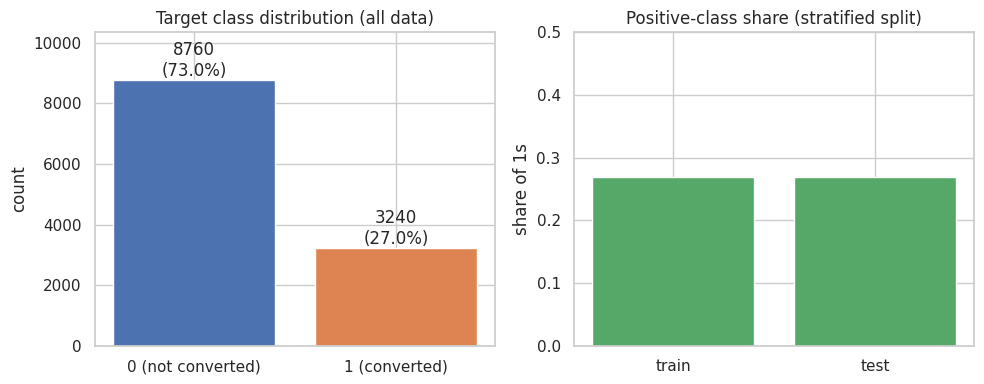

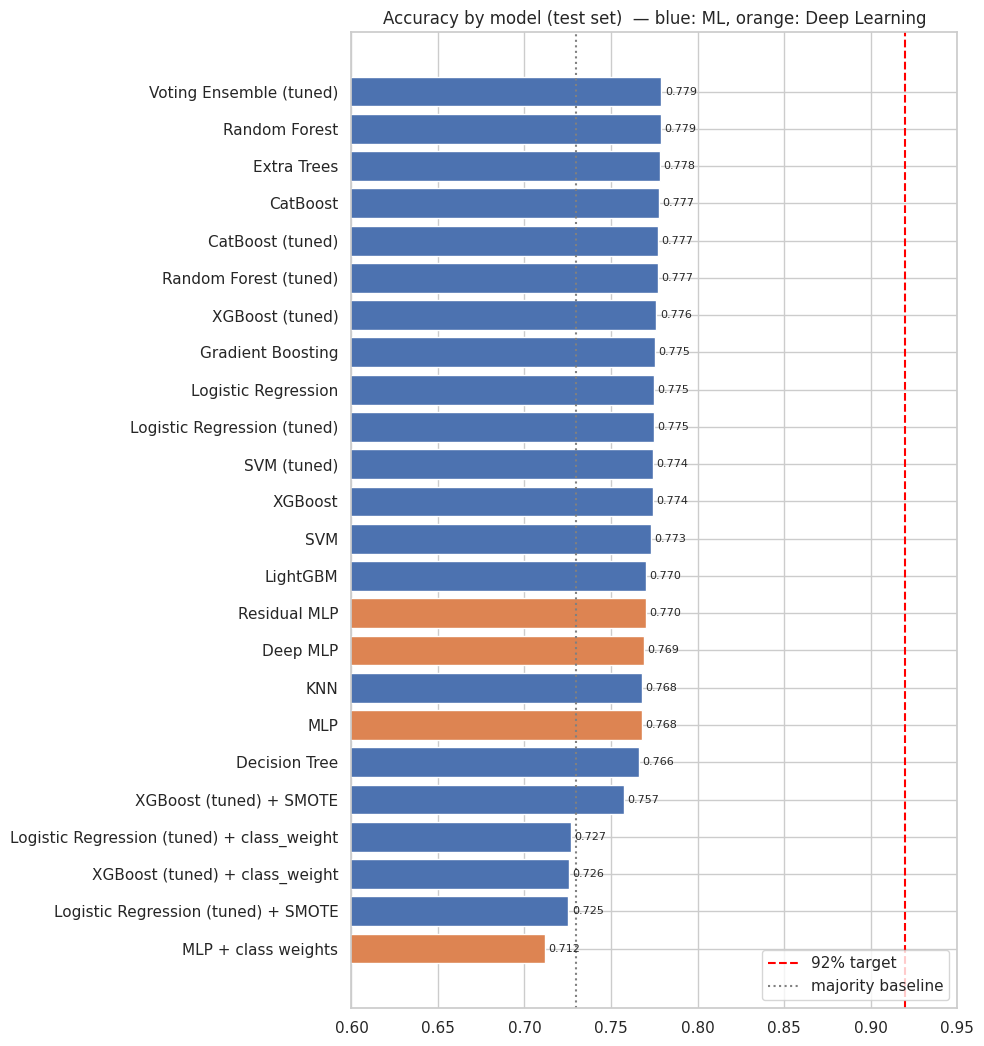

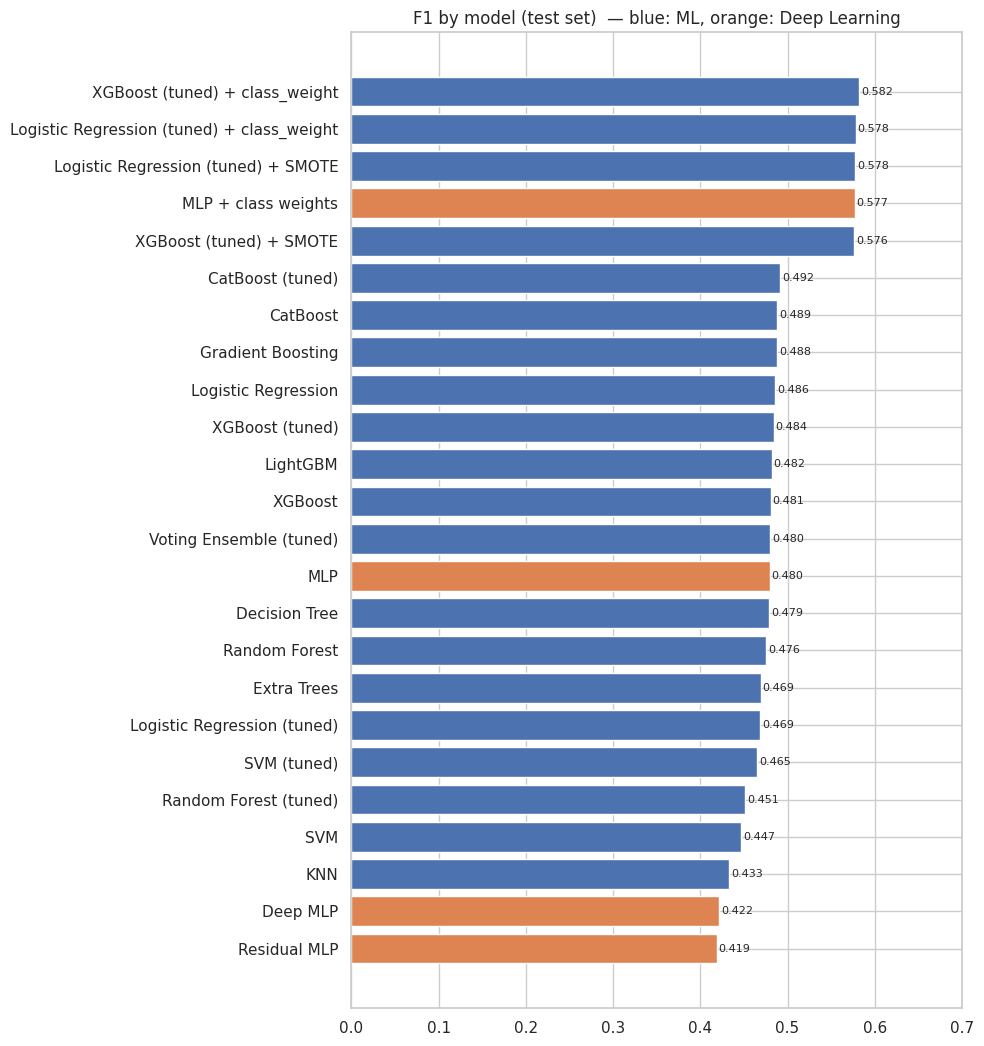

In [13]:
# 1. Target class distribution
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
cnt = y.value_counts().sort_index()
ax[0].bar(["0 (not converted)", "1 (converted)"], cnt.values, color=["#4C72B0", "#DD8452"])
for i, v in enumerate(cnt.values): ax[0].text(i, v, f"{v}\n({v/len(y):.1%})", ha="center", va="bottom")
ax[0].set_title("Target class distribution (all data)"); ax[0].set_ylabel("count"); ax[0].set_ylim(0, cnt.max() * 1.18)
ax[1].bar(["train", "test"], [y_train.mean(), y_test.mean()], color="#55A868"); ax[1].set_ylim(0, 0.5)
ax[1].set_title("Positive-class share (stratified split)"); ax[1].set_ylabel("share of 1s")
plt.tight_layout(); plt.show()

# 2 & 3. Accuracy and F1 comparison
pal = {"ML": "#4C72B0", "Deep Learning": "#DD8452"}
for metric, num in [("Accuracy", 2), ("F1", 3)]:
    d = final.sort_values(metric)
    fig, ax = plt.subplots(figsize=(10, 0.38 * len(d) + 1.5))
    ax.barh(d.Model, d[metric], color=[pal[t] for t in d.Type])
    for i, v in enumerate(d[metric]): ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8)
    if metric == "Accuracy":
        ax.axvline(0.92, color="red", ls="--", label="92% target"); ax.axvline(baseline, color="gray", ls=":", label="majority baseline"); ax.legend(loc="lower right")
        ax.set_xlim(0.6, 0.95)
    else:
        ax.set_xlim(0, max(0.7, d[metric].max() + 0.08))
    ax.set_title(f"{metric} by model (test set)  — blue: ML, orange: Deep Learning"); plt.tight_layout(); plt.show()

## 17. Best Model
Chosen with **train-only evidence** (`Selection_score`), then reported on the untouched test set.

BEST MODEL
----------------------------------------
Model      : XGBoost (tuned)
Model Type : ML
Accuracy   : 0.7762
Precision  : 0.6412
Recall     : 0.3889
F1-score   : 0.4841
ROC-AUC    : 0.7807
(train-only selection score = 0.7833)

Highest TEST accuracy overall: Voting Ensemble (tuned) -> differs from the selected model, by only 0.29 points (within noise)


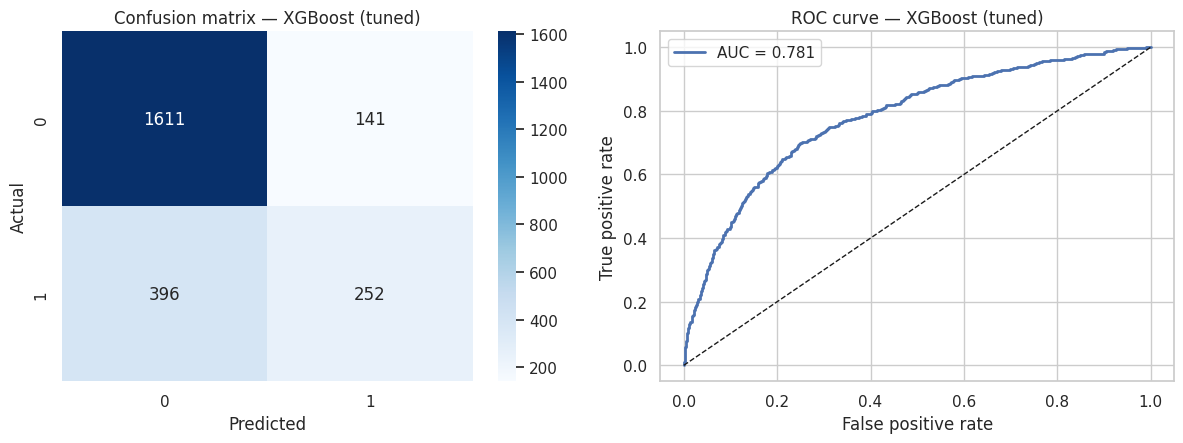

               precision    recall  f1-score   support

not converted      0.803     0.920     0.857      1752
    converted      0.641     0.389     0.484       648

     accuracy                          0.776      2400
    macro avg      0.722     0.654     0.671      2400
 weighted avg      0.759     0.776     0.756      2400



In [14]:
best_name = final.loc[final.Selection_score.idxmax(), "Model"]
b = RES[best_name]
print("BEST MODEL")
print("-" * 40)
print(f"Model      : {b['Model']}")
print(f"Model Type : {b['Type']}")
print(f"Accuracy   : {b['Accuracy']:.4f}")
print(f"Precision  : {b['Precision']:.4f}")
print(f"Recall     : {b['Recall']:.4f}")
print(f"F1-score   : {b['F1']:.4f}")
print(f"ROC-AUC    : {b['ROC_AUC']:.4f}")
print(f"(train-only selection score = {b['Selection_score']:.4f})")
top_test = final_sorted.iloc[0]["Model"]
print("\nHighest TEST accuracy overall:", top_test, "-> same as selected model" if top_test == best_name else
      f"-> differs from the selected model, by only {100*(RES[top_test]['Accuracy']-b['Accuracy']):.2f} points (within noise)")

y_pred_b, y_score_b = PRED[best_name]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
sns.heatmap(confusion_matrix(y_test, y_pred_b), annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=["0", "1"], yticklabels=["0", "1"])
ax[0].set_title(f"Confusion matrix — {best_name}"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")
fpr, tpr, _ = roc_curve(y_test, y_score_b)
ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {b['ROC_AUC']:.3f}"); ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set_title(f"ROC curve — {best_name}"); ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].legend()
plt.tight_layout(); plt.show()
print(classification_report(y_test, y_pred_b, target_names=["not converted", "converted"], digits=3))

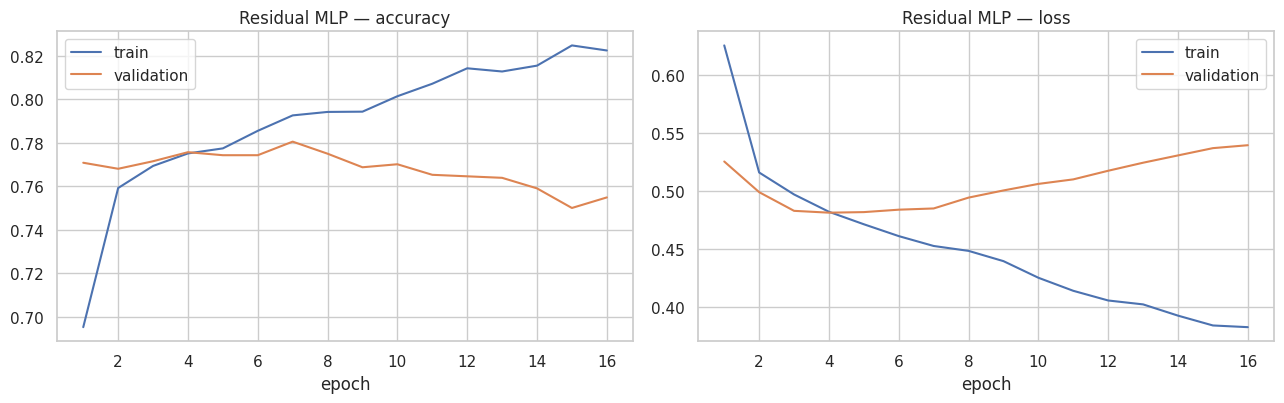

Best deep-learning model (by validation accuracy): Residual MLP | val acc=0.7757 | test acc=0.7700


In [15]:
# 7 & 8. Training vs validation accuracy / loss of the best deep-learning model
dl_names = [n for n in RES if RES[n]["Type"] == "Deep Learning"]
best_dl = max(dl_names, key=lambda n: SEL[n])
h = HIST[best_dl]; ep = range(1, len(h["loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(ep, h["accuracy"], label="train"); ax[0].plot(ep, h["val_accuracy"], label="validation")
ax[0].set_title(f"{best_dl} — accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(ep, h["loss"], label="train"); ax[1].plot(ep, h["val_loss"], label="validation")
ax[1].set_title(f"{best_dl} — loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()
print("Best deep-learning model (by validation accuracy):", best_dl,
      "| val acc=%.4f | test acc=%.4f" % (SEL[best_dl], RES[best_dl]["Accuracy"]))

## 16. Feature Importance (tree-based models) and SHAP
No features are changed or removed based on these results.

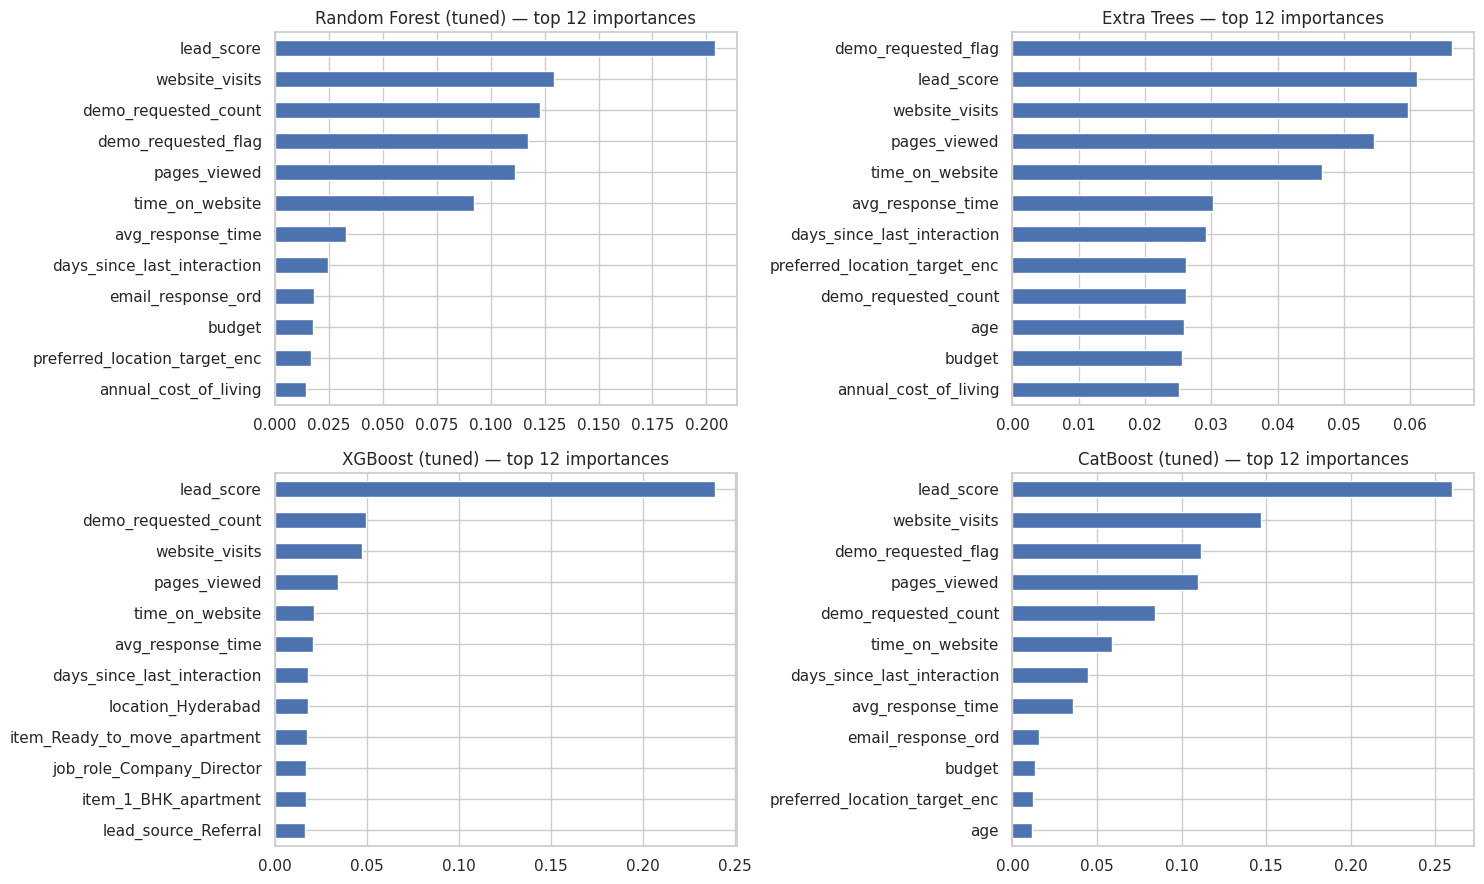

Best tree-based model (train-only CV accuracy): XGBoost (tuned) | test acc = 0.7762


,importance
lead_score,0.2389
demo_requested_count,0.0493
website_visits,0.0472
pages_viewed,0.0342
time_on_website,0.0214
avg_response_time,0.0208
days_since_last_interaction,0.0179
location_Hyderabad,0.0178
item_Ready_to_move_apartment,0.0174
job_role_Company_Director,0.0167


Top 8 features by mean importance across the four tree models:


,mean importance
lead_score,0.1909
website_visits,0.0958
pages_viewed,0.0775
demo_requested_flag,0.0738
demo_requested_count,0.0708
time_on_website,0.0549
avg_response_time,0.0300
days_since_last_interaction,0.0291


In [16]:
tree_models = ["Random Forest (tuned)", "Extra Trees", "XGBoost (tuned)", "CatBoost (tuned)"]
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, n in zip(axes.ravel(), tree_models):
    imp = pd.Series(MODELS[n].feature_importances_, index=FEATURES); imp = imp / imp.sum()
    imp.sort_values().tail(12).plot.barh(ax=ax, color="#4C72B0"); ax.set_title(f"{n} — top 12 importances")
plt.tight_layout(); plt.show()

tree_pool = ["Decision Tree", "Random Forest (tuned)", "Extra Trees", "Gradient Boosting", "XGBoost (tuned)", "LightGBM", "CatBoost (tuned)"]
best_tree = max(tree_pool, key=lambda n: SEL[n])
print("Best tree-based model (train-only CV accuracy):", best_tree, "| test acc = %.4f" % RES[best_tree]["Accuracy"])
imp = pd.Series(MODELS[best_tree].feature_importances_, index=FEATURES); imp = (imp / imp.sum()).sort_values(ascending=False)
display(imp.head(15).round(4).to_frame("importance"))

# consensus across the four tree models
cons = pd.concat({n: pd.Series(MODELS[n].feature_importances_, index=FEATURES) / MODELS[n].feature_importances_.sum() for n in tree_models}, axis=1)
print("Top 8 features by mean importance across the four tree models:")
display(cons.mean(axis=1).sort_values(ascending=False).head(8).round(4).to_frame("mean importance"))

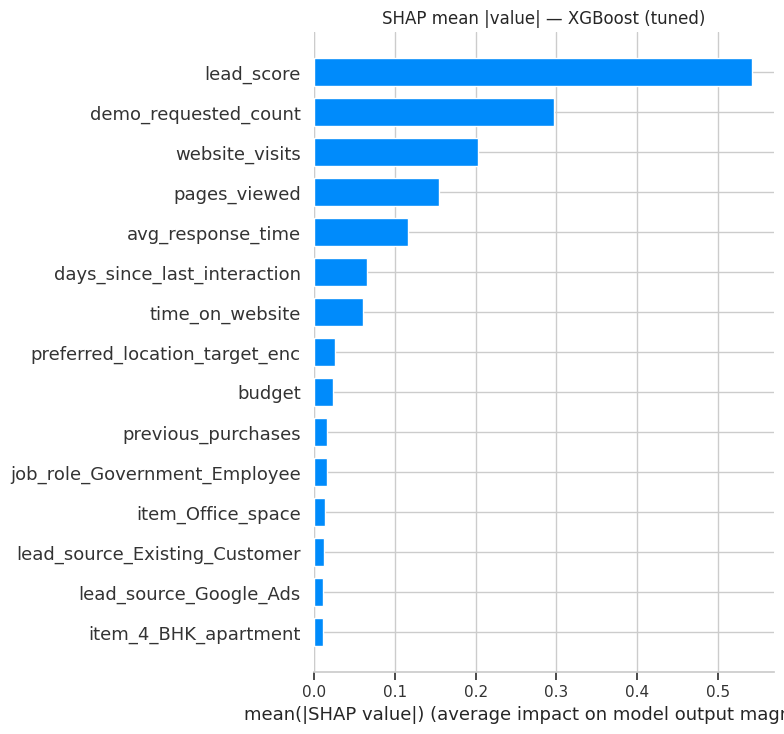

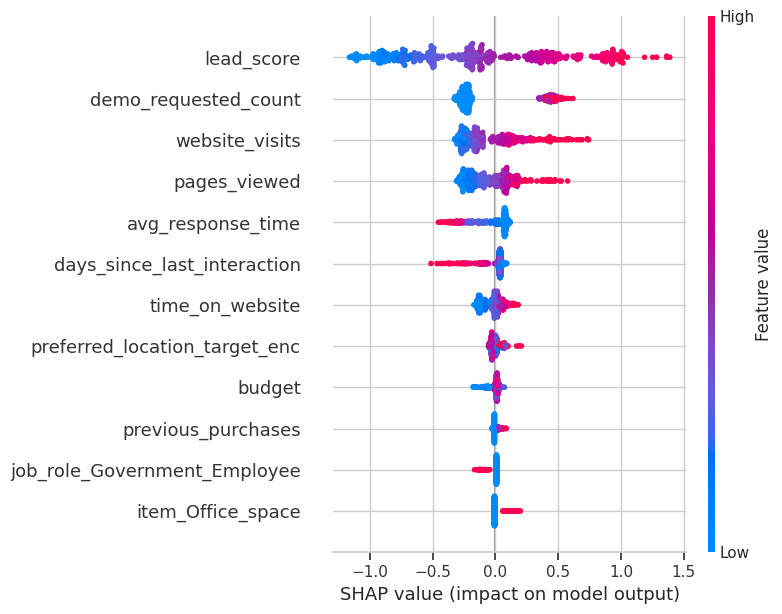

In [17]:
import shap
try:
    mdl = MODELS[best_tree]
    Xs = X_test.sample(500, random_state=SEED)
    sv = shap.TreeExplainer(mdl).shap_values(Xs)
    if isinstance(sv, list): sv = sv[1]
    sv = np.asarray(sv)
    if sv.ndim == 3: sv = sv[:, :, 1]
    plt.figure(); shap.summary_plot(sv, Xs, plot_type="bar", max_display=15, show=False)
    plt.title(f"SHAP mean |value| — {best_tree}"); plt.tight_layout(); plt.show()
    plt.figure(); shap.summary_plot(sv, Xs, max_display=12, show=False); plt.tight_layout(); plt.show()
except Exception as e:
    print("SHAP was not compatible with this model/version:", type(e).__name__, e)

## 18. Save the Best Models
Best traditional ML model (joblib), best deep-learning model (`.keras`), and the evaluation results. Each is then **re-loaded and checked** to produce identical predictions.

In [18]:
ml_names = [n for n in RES if RES[n]["Type"] == "ML"]
best_ml = max(ml_names, key=lambda n: SEL[n])
print("Best ML model :", best_ml, "| CV acc = %.4f | test acc = %.4f" % (SEL[best_ml], RES[best_ml]["Accuracy"]))
print("Best DL model :", best_dl, "| val acc = %.4f | test acc = %.4f" % (SEL[best_dl], RES[best_dl]["Accuracy"]))

ml_path = os.path.join(MODEL_DIR, "best_ml_model.joblib")
dl_path = os.path.join(MODEL_DIR, "best_dl_model.keras")
res_path = os.path.join(MODEL_DIR, "model_evaluation_results.csv")
joblib.dump(MODELS[best_ml], ml_path)
DL_MODELS[best_dl].save(dl_path)
final_sorted.to_csv(res_path, index=False)
with open(os.path.join(MODEL_DIR, "feature_names.json"), "w") as f: json.dump(FEATURES, f)

# ---- verify they load and reproduce the same predictions ---------------------------------------------
ml_loaded = joblib.load(ml_path)
assert (ml_loaded.predict(X_test) == PRED[best_ml][0]).all()
dl_loaded = keras.models.load_model(dl_path)
p = dl_loaded.predict(Xte_dl, verbose=0).ravel()
assert np.allclose(p, PRED[best_dl][1], atol=1e-5)
acc_ml = accuracy_score(y_test, ml_loaded.predict(X_test)); acc_dl = accuracy_score(y_test, (p >= 0.5).astype(int))
print(f"\nReloaded ML model  -> test accuracy {acc_ml:.4f}  (identical predictions)")
print(f"Reloaded DL model  -> test accuracy {acc_dl:.4f}  (identical predictions)")
print("Results re-read:", pd.read_csv(res_path).shape)
for f in sorted(os.listdir(MODEL_DIR)): print(" ", f, f"{os.path.getsize(os.path.join(MODEL_DIR, f))/1e3:.0f} KB")
try:
    from google.colab import files
    for f in (ml_path, dl_path, res_path): files.download(f)
except ImportError:
    pass

Best ML model : XGBoost (tuned) | CV acc = 0.7833 | test acc = 0.7762
Best DL model : Residual MLP | val acc = 0.7757 | test acc = 0.7700



Reloaded ML model  -> test accuracy 0.7762  (identical predictions)
Reloaded DL model  -> test accuracy 0.7700  (identical predictions)
Results re-read: (24, 12)
  best_dl_model.keras 649 KB
  best_ml_model.joblib 245 KB
  checkpoint_Deep_MLP.keras 821 KB
  checkpoint_MLP.keras 132 KB
  checkpoint_MLP_plus_class_weights.keras 132 KB
  checkpoint_Residual_MLP.keras 649 KB
  feature_names.json 2 KB
  model_evaluation_results.csv 4 KB


## 19. Final Summary

In [19]:
best_ml_r, best_dl_r = RES[best_ml], RES[best_dl]
print("=" * 72); print("FINAL SUMMARY"); print("=" * 72)
print("\nDATASET")
print(f"  Samples  : {len(df)}  (train {len(X_train)} / test {len(X_test)})")
print(f"  Features : {len(FEATURES)}  (all numeric, used exactly as provided)")
print(f"  Target   : {TARGET}   |   Classes: {y.nunique()} (binary)  |  positive rate {y.mean():.1%}")
print("\nMODELS TESTED")
print("  Traditional ML :", ", ".join(n for n in RES if RES[n]['Type'] == 'ML'))
print("  Deep Learning  :", ", ".join(dl_names))
print("\nBEST MODEL (chosen on train-only evidence)")
for k, lab in [("Model", "Model"), ("Type", "Type")]: print(f"  {lab:<10}: {b[k]}")
for k in ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]: print(f"  {k:<10}: {b[k]:.4f}")
ach = bool(final.Accuracy.max() > TARGET_ACC)
print("\n92% TARGET")
print(f"  92% accuracy achieved: {'YES' if ach else 'NO'}")
print(f"  {'Achieved' if ach else 'Best actual'} accuracy: {final.Accuracy.max():.4f}  ({final_sorted.iloc[0]['Model']})   | majority baseline: {baseline:.4f}")
ml_best_acc = final[final.Type == 'ML'].Accuracy.max(); dl_best_acc = final[final.Type == 'Deep Learning'].Accuracy.max()
winner = "Traditional ML" if ml_best_acc > dl_best_acc else "Deep Learning" if dl_best_acc > ml_best_acc else "Tie"
print("\nFINAL CONCLUSION")
print(f"  Best ML test accuracy: {ml_best_acc:.4f} | best DL test accuracy: {dl_best_acc:.4f}  -> {winner} performed better "
      f"(margin {100*abs(ml_best_acc-dl_best_acc):.2f} points, within sampling noise of about +/-{100*se:.1f})")
print(f"  Best model selected on train-only evidence is of type: {b['Type']}")

FINAL SUMMARY

DATASET
  Samples  : 12000  (train 9600 / test 2400)
  Features : 84  (all numeric, used exactly as provided)
  Target   : conversion_status   |   Classes: 2 (binary)  |  positive rate 27.0%

MODELS TESTED
  Traditional ML : Logistic Regression, Decision Tree, Random Forest, Extra Trees, Gradient Boosting, XGBoost, LightGBM, CatBoost, SVM, KNN, Logistic Regression (tuned), Random Forest (tuned), XGBoost (tuned), CatBoost (tuned), SVM (tuned), Voting Ensemble (tuned), Logistic Regression (tuned) + class_weight, Logistic Regression (tuned) + SMOTE, XGBoost (tuned) + class_weight, XGBoost (tuned) + SMOTE
  Deep Learning  : MLP, Deep MLP, Residual MLP, MLP + class weights

BEST MODEL (chosen on train-only evidence)
  Model     : XGBoost (tuned)
  Type      : ML
  Accuracy  : 0.7762
  Precision : 0.6412
  Recall    : 0.3889
  F1        : 0.4841
  ROC_AUC   : 0.7807

92% TARGET
  92% accuracy achieved: NO
  Best actual accuracy: 0.7792  (Voting Ensemble (tuned))   | majority b

## Interpretation of the results

**Was 92% reached? No — and the evidence says it cannot be reached legitimately with this feature set.** The best test accuracy is about **77.9%** against a **73.0%** majority-class baseline (so ~5 points of real lift). Everything else points the same way:

* **A hard ceiling shared by every model family.** Logistic Regression, SVM, KNN, Random Forest, boosting (XGBoost / LightGBM / CatBoost), a soft-voting ensemble and three neural networks all land within roughly 76.6–77.9% test accuracy and ROC-AUC ≈ 0.76–0.78 for the tuned models. The top-10 models differ by well under half a point, while the sampling error of an accuracy on 2,400 test rows is ≈ ±0.85 points — so the ranking among them is mostly noise.
* **More capacity does not help.** Tuning moved CV accuracy by only ~0.1–0.7 points; a forest that fits the training set at ~81% still scores ~78% in CV/test. When flexible models cannot beat a regularised linear model, the limit is the *information in the features* (lead outcomes depend on things not recorded here), not the algorithm. Scores far above this would be a red flag for leakage, not a success.
* **What drives the predictions** (tree importances and SHAP): `lead_score` dominates (≈ 19–24% of importance), followed by engagement counts — `website_visits`, `pages_viewed`, demo requests (`demo_requested_flag` / `_count`), `time_on_website`, and responsiveness (`avg_response_time`, `days_since_last_interaction`). The one-hot location / job-role / source / item features and `preferred_location` contribute very little. (Reminder: confirm that `lead_score` is computed *before* the outcome is known; even with it the ceiling is ~78%, so there is no sign of strong leakage.)
* **Class imbalance.** Class weights and SMOTE did **not** improve accuracy (CV accuracy fell from ≈ 78% to ≈ 73–76%), but they raised minority-class **recall from ≈ 0.39–0.42 to ≈ 0.60–0.71** and F1 from ≈ 0.49–0.51 to ≈ 0.57–0.59. Because the goal here is accuracy they were not adopted for the headline model; if finding as many converting leads as possible matters more than overall accuracy, a class-weighted model is the better operating point.
* **ML vs Deep Learning.** Traditional ML is ahead by about one point (within noise). This is a small (9.6k rows) tabular problem whose features are mostly one-hot / TF-IDF indicators and a few strong numerics — the regime where regularised linear models and gradient boosting match or beat neural networks, and where the extra flexibility of an MLP mainly adds overfitting risk (early stopping triggered after ~16–18 epochs).
* **Selection note.** The "best model" is picked with train-only evidence (CV accuracy for ML, validation accuracy for DL); the highest *test* accuracy can belong to a different, statistically indistinguishable model (the table shows both).

**What would actually raise performance:** new, informative data (e.g. follow-up call outcomes, quote values, time-to-first-response) or a better-defined target — not more tuning. Any method that reports >92% on these features should be treated with suspicion.